# HAL Aircraft Inventory — Consumption Forecasting & Risk Analysis

This notebook predicts each product's consumption for 2026 and works out what
needs to be reordered, using two AI/ML models:

1. **Random Forest Regressor** — forecasts monthly consumption per product
2. **Random Forest Classifier** — predicts the probability of a stockout next month

The three input CSVs (`consumption.csv`,
`inventory_stock.csv`, `products.csv`) were created for this project rather
than supplied by HAL.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from statsmodels.tsa.holtwinters import ExponentialSmoothing

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)

## 1. Fix the product data

Some products in the raw `products.csv` had an expiry date in the past, yet
`inventory_stock.csv` shows stock still being received for them through
2025. Since this dataset was created for the project, that's corrected here
rather than left as a contradiction that would wrongly flag 121 products as
"expired stock."

In [2]:
# This cell allows the three CSV files to be uploaded in Google Colab.
# Upload:
# 1. consumption.csv
# 2. inventory_stock.csv
# 3. products.csv

from google.colab import files

uploaded = files.upload()

Saving consumption.csv to consumption.csv
Saving inventory_stock.csv to inventory_stock.csv
Saving products.csv to products.csv


In [3]:
# This cell reads the three datasets.
# Dates are converted into datetime format so that we can perform
# time-series analysis correctly.

consumption = pd.read_csv(
    "consumption.csv",
    parse_dates=["month"]
)

inventory = pd.read_csv(
    "inventory_stock.csv",
    parse_dates=["month"]
)

products = pd.read_csv(
    "products.csv",
    parse_dates=["manufacturing_date", "expiry_date"]
)

print("Datasets loaded successfully.")

Datasets loaded successfully.


In [4]:
consumption = pd.read_csv("consumption.csv", parse_dates=["month"])
inventory = pd.read_csv("inventory_stock.csv", parse_dates=["month"])

print("Consumption shape:", consumption.shape)
print("Inventory shape:", inventory.shape)
print("Products shape:", products.shape)

print("\nMissing values — consumption:", consumption.isnull().sum().sum(),
      "| inventory:", inventory.isnull().sum().sum(),
      "| products:", products.isnull().sum().sum())

print("Duplicate rows — consumption:", consumption.duplicated().sum(),
      "| inventory:", inventory.duplicated().sum())

print("\nDate range:", inventory["month"].min().date(), "to", inventory["month"].max().date())
print("Number of products:", products["product_id"].nunique())

Consumption shape: (18000, 6)
Inventory shape: (18000, 8)
Products shape: (500, 9)

Missing values — consumption: 0 | inventory: 0 | products: 0
Duplicate rows — consumption: 0 | inventory: 0

Date range: 2023-01-01 to 2025-12-01
Number of products: 500


In [5]:
# This cell displays the first few rows of each dataset.
# We use this to visually confirm the data format.

print("CONSUMPTION")
display(consumption.head())

print("\nINVENTORY")
display(inventory.head())

print("\nPRODUCTS")
display(products.head())

CONSUMPTION


,record_id,product_id,month,quantity_consumed,department,unit_cost_at_time_inr
0,1,P0001,2023-01-01,226,Assembly Line 1,412.17
1,2,P0001,2023-02-01,220,Flight Test Unit,392.12
2,3,P0001,2023-03-01,307,Overhaul Base,419.31
3,4,P0001,2023-04-01,376,Assembly Line 1,415.93
4,5,P0001,2023-05-01,476,Assembly Line 2,402.06



INVENTORY


,product_id,month,opening_stock,quantity_received,quantity_consumed,closing_stock,reorder_level,lead_time_days
0,P0001,2023-01-01,1134,0,226,908,883,60
1,P0001,2023-02-01,908,0,220,688,883,60
2,P0001,2023-03-01,688,632,307,1013,883,60
3,P0001,2023-04-01,1013,0,376,637,883,60
4,P0001,2023-05-01,637,478,476,639,883,60



PRODUCTS


,product_id,product_name,category,manufacturing_date,shelf_life_days,expiry_date,unit_cost_inr,criticality,supplier_id
0,P0001,Fasteners-Hardware-0001,Fasteners & Hardware,2022-10-22,2958,2030-11-27,400.31,Medium,SUP07
1,P0002,Rotor-Transmission-0002,Rotor & Transmission,2022-10-06,1269,2026-03-28,96158.03,Medium,SUP08
2,P0003,Composite-Materials-0003,Composite Materials,2022-01-23,395,2026-05-13,27082.87,Low,SUP06
3,P0004,Avionics-Avionics-0004,Avionics,2021-09-29,1275,2027-01-14,52728.49,Medium,SUP12
4,P0005,Cockpit-Instruments-0005,Cockpit Instruments,2021-02-19,2417,2027-10-03,31880.79,High,SUP16


In [6]:
# This cell checks whether any important values are missing.
# Missing values can cause errors during machine learning.

print("Consumption missing values:")
display(consumption.isnull().sum())

print("\nInventory missing values:")
display(inventory.isnull().sum())

print("\nProducts missing values:")
display(products.isnull().sum())

Consumption missing values:


,0
record_id,0
product_id,0
month,0
quantity_consumed,0
department,0
unit_cost_at_time_inr,0



Inventory missing values:


,0
product_id,0
month,0
opening_stock,0
quantity_received,0
quantity_consumed,0
closing_stock,0
reorder_level,0
lead_time_days,0



Products missing values:


,0
product_id,0
product_name,0
category,0
manufacturing_date,0
shelf_life_days,0
expiry_date,0
unit_cost_inr,0
criticality,0
supplier_id,0


## 3. Build features

Features are built **only from past consumption** (lag values and rolling
averages) plus the calendar month. Current-month stock columns
(`closing_stock`, `opening_stock`, etc.) are deliberately left out of the
consumption model: since we forecast 12 months ahead recursively, using
today's stock as a feature would mean freezing today's stock level into
every future month, which isn't realistic. Stock is brought back in later
(Section 8) for the actual reorder-quantity maths, where it belongs.

### Forecasting data preparation

The forecasting pipeline now uses all three datasets:
- `consumption.csv` → historical consumption used to build demand features and the prediction target
- `inventory_stock.csv` → stock, reorder level and lead-time information
- `products.csv` → product master information such as category, criticality, expiry and cost

Because `inventory_stock.csv` also contains `quantity_consumed`, we compare the two consumption sources before using `consumption.csv` as the forecasting source.


In [7]:
# Build the modelling dataset using all three input datasets.
# consumption.csv provides the historical consumption used for forecasting.
# inventory_stock.csv provides inventory/stock information.
# products.csv provides product master information.

# First combine inventory and product information.
data = inventory.merge(products, on="product_id", how="left")

# Bring in the historical consumption dataset using product_id + month.
# The inventory file also contains quantity_consumed, so we keep it temporarily
# to check that the two historical sources agree.
consumption_for_merge = consumption[
    ["product_id", "month", "quantity_consumed"]
].rename(columns={"quantity_consumed": "consumption_quantity"})

data = data.merge(
    consumption_for_merge,
    on=["product_id", "month"],
    how="left",
    validate="one_to_one"
)

# Check whether the two datasets' consumption values agree.
consumption_check = (
    data["quantity_consumed"] - data["consumption_quantity"]
).abs()

print("Consumption rows matched:",
      data["consumption_quantity"].notna().sum(), "/", len(data))
print("Maximum difference between consumption.csv and inventory_stock.csv:",
      consumption_check.max())

# Use consumption.csv as the forecasting consumption source.
data["quantity_consumed"] = data["consumption_quantity"]
data = data.drop(columns=["consumption_quantity"])

data = data.sort_values(["product_id", "month"]).reset_index(drop=True)

# Create lag and rolling-demand features from the historical consumption data.
g = data.groupby("product_id")["quantity_consumed"]

for lag in [1, 2, 3, 6, 12]:
    data[f"lag_{lag}"] = g.shift(lag)

for w in [3, 6, 12]:
    data[f"rolling_mean_{w}"] = g.transform(
        lambda x: x.shift(1).rolling(w).mean()
    )

data["rolling_std_3"] = g.transform(
    lambda x: x.shift(1).rolling(3).std()
)

data["month_number"] = data["month"].dt.month
data["quarter"] = data["month"].dt.quarter

# Target: next month's actual consumption.
data["target_next_month"] = (
    data.groupby("product_id")["quantity_consumed"].shift(-1)
)

FEATURES = [
    "lag_1", "lag_2", "lag_3", "lag_6", "lag_12",
    "rolling_mean_3", "rolling_mean_6", "rolling_mean_12",
    "rolling_std_3", "month_number", "quarter"
]

ml_data = data.dropna(
    subset=FEATURES + ["target_next_month"]
).copy()

print("ML dataset shape:", ml_data.shape)


Consumption rows matched: 18000 / 18000
Maximum difference between consumption.csv and inventory_stock.csv: 0
ML dataset shape: (11500, 28)


In [8]:
# A separate, larger feature set for the STOCKOUT CLASSIFIER (Section 7).
# Unlike the consumption forecast, the classifier predicts only ONE month
# ahead, so using this month's real stock numbers is legitimate there.
data["criticality_encoded"] = data["criticality"].map({"Low": 1, "Medium": 2, "High": 3})

data["stock_gap"] = data["closing_stock"] - data["reorder_level"]

data["months_of_stock"] = (
    data["closing_stock"] /
    data["rolling_mean_3"].replace(0, np.nan)
)

STOCK_FEATURES = FEATURES + [
    "opening_stock",
    "quantity_received",
    "closing_stock",
    "reorder_level",
    "lead_time_days",
    "unit_cost_inr",
    "criticality_encoded",
    "stock_gap",
    "months_of_stock"
]

## 4. Compare models on 2025 (one-month-ahead, fair comparison)

All four models are trained on 2023–2024 and evaluated on the **same** 2025
rows, predicting one month ahead: Random Forest (our main AI/ML model),
Linear Regression, a naive "same month last year" baseline, and
Holt-Winters as a classical time-series benchmark.

In [9]:
train = ml_data[ml_data["month"] < "2025-01-01"]
test = ml_data[ml_data["month"] >= "2025-01-01"]

X_train, y_train = train[FEATURES], train["target_next_month"]
X_test, y_test = test[FEATURES], test["target_next_month"]

results = []

# Model 1: Random Forest
rf = RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=2,
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = np.maximum(rf.predict(X_test), 0)
results.append(("Random Forest", mean_absolute_error(y_test, pred_rf),
                 np.sqrt(mean_squared_error(y_test, pred_rf)), r2_score(y_test, pred_rf)))

# Model 2: Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = np.maximum(lr.predict(X_test), 0)
results.append(("Linear Regression", mean_absolute_error(y_test, pred_lr),
                 np.sqrt(mean_squared_error(y_test, pred_lr)), r2_score(y_test, pred_lr)))

# Model 3: Naive baseline
pred_naive = test["lag_12"]
results.append(("Naive (same month last year)", mean_absolute_error(y_test, pred_naive),
                 np.sqrt(mean_squared_error(y_test, pred_naive)), r2_score(y_test, pred_naive)))

# Model 4: Holt-Winters, sample of 100 products
hw_actual, hw_pred = [], []
sample_products = products["product_id"].sort_values().head(100).tolist()
for pid in sample_products:
    series = data[data["product_id"] == pid].sort_values("month")["quantity_consumed"].values
    if len(series) < 24:
        continue
    try:
        m = ExponentialSmoothing(series[:24], trend="add", seasonal="add",
                                  seasonal_periods=12, initialization_method="estimated")
        fc = m.fit().forecast(len(series[24:36]))
        hw_actual.extend(series[24:36])
        hw_pred.extend(np.maximum(fc, 0))
    except Exception:
        continue
results.append(("Holt-Winters (100-product sample)", mean_absolute_error(hw_actual, hw_pred),
                 np.sqrt(mean_squared_error(hw_actual, hw_pred)), np.nan))

model_comparison = pd.DataFrame(results, columns=["Model", "MAE", "RMSE", "R2"])
model_comparison

,Model,MAE,RMSE,R2
0,Random Forest,5.429040,19.630979,0.946129
1,Linear Regression,4.573458,16.060964,0.963941
2,Naive (same month last year),7.849455,26.472655,0.902035
3,Holt-Winters (100-product sample),3.935582,15.126478,NaN


## 4b. Backtest the real use case: 12-month recursive forecast



In [10]:
def recursive_forecast(history_df, model, features, start_month, n_months):
    hist = {
        pid: list(x.sort_values("month")["quantity_consumed"])
        for pid, x in history_df.groupby("product_id")
    }
    out = []
    months = pd.date_range(start_month, periods=n_months, freq="MS")
    for mo in months:
        rows, order = [], []
        for pid, h in hist.items():
            if len(h) < 12:
                continue
            rows.append({
                "lag_1": h[-1], "lag_2": h[-2], "lag_3": h[-3],
                "lag_6": h[-6], "lag_12": h[-12],
                "rolling_mean_3": np.mean(h[-3:]),
                "rolling_mean_6": np.mean(h[-6:]),
                "rolling_mean_12": np.mean(h[-12:]),
                "rolling_std_3": np.std(h[-3:]),
                "month_number": mo.month, "quarter": mo.quarter
            })
            order.append(pid)
        X = pd.DataFrame(rows)[features]
        preds = np.maximum(model.predict(X), 0)
        for pid, v in zip(order, preds):
            out.append({"product_id": pid, "month": mo, "predicted_consumption": v})
            hist[pid].append(v)
    return pd.DataFrame(out)

backtest_train = ml_data[ml_data["month"] < "2024-12-01"]
rf_bt = RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=2,
                               random_state=42, n_jobs=-1)
rf_bt.fit(backtest_train[FEATURES], backtest_train["target_next_month"])

history_for_bt = data[data["month"] < "2025-01-01"]
bt_forecast = recursive_forecast(history_for_bt, rf_bt, FEATURES, "2025-01-01", 12)

actual_2025 = data[data["month"] >= "2025-01-01"][["product_id", "month", "quantity_consumed"]]
bt_compare = bt_forecast.merge(actual_2025, on=["product_id", "month"])

bt_annual = bt_compare.groupby("product_id").agg(
    predicted=("predicted_consumption", "sum"), actual=("quantity_consumed", "sum")
)
bt_annual["pct_error"] = (bt_annual["predicted"] - bt_annual["actual"]).abs() / bt_annual["actual"].replace(0, np.nan)

naive_annual = data[(data["month"] >= "2024-01-01") & (data["month"] < "2025-01-01")] \
    .groupby("product_id")["quantity_consumed"].sum().reindex(bt_annual.index)
naive_pct_error = (naive_annual - bt_annual["actual"]).abs() / bt_annual["actual"].replace(0, np.nan)

print("Total actual 2025 consumption   :", f"{bt_annual['actual'].sum():,.0f}")
print("Total RF forecast for 2025      :", f"{bt_annual['predicted'].sum():,.0f}")
print("Total naive 'repeat 2024' guess :", f"{naive_annual.sum():,.0f}")
print("RF median per-product % error   :", f"{bt_annual['pct_error'].median()*100:.1f}%")
print("Naive median per-product % error:", f"{naive_pct_error.median()*100:.1f}%")

Total actual 2025 consumption   : 183,566
Total RF forecast for 2025      : 203,685
Total naive 'repeat 2024' guess : 160,738
RF median per-product % error   : 12.5%
Naive median per-product % error: 18.2%


## 5. Retrain the final model on all data through 2025

The model used for the actual 2026 forecast is retrained on the full
2023–2025 history (not just 2023–2024 as in the comparison above), so it
uses the most recent information available.

In [11]:
X_all = ml_data[FEATURES]
y_all = ml_data["target_next_month"]

rf_final = RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=2,
                                  random_state=42, n_jobs=-1)
rf_final.fit(X_all, y_all)
print("Final Random Forest trained on all data through 2025.")

Final Random Forest trained on all data through 2025.


## 6. Forecast 2026 (recursive, all 500 products)

In [12]:
# Monthly forecast for one product
forecast_2026 = recursive_forecast(data, rf_final, FEATURES, "2026-01-01", 12)
forecast_2026["predicted_consumption"] = forecast_2026["predicted_consumption"].round(0)
display(
    forecast_2026[
        forecast_2026["product_id"] == "P0001"
    ].sort_values("month")
)

,product_id,month,predicted_consumption
0,P0001,2026-01-01,285.0
500,P0001,2026-02-01,340.0
1000,P0001,2026-03-01,395.0
1500,P0001,2026-04-01,360.0
2000,P0001,2026-05-01,366.0
2500,P0001,2026-06-01,362.0
3000,P0001,2026-07-01,356.0
3500,P0001,2026-08-01,348.0
4000,P0001,2026-09-01,332.0
4500,P0001,2026-10-01,347.0


In [13]:
forecast_2026 = recursive_forecast(data, rf_final, FEATURES, "2026-01-01", 12)
forecast_2026["predicted_consumption"] = forecast_2026["predicted_consumption"].round(0)
print("2026 forecast rows:", len(forecast_2026), "(expected", 500 * 12, ")")

annual_forecast_2026 = (
    forecast_2026.groupby("product_id")["predicted_consumption"]
    .sum().reset_index()
    .rename(columns={"predicted_consumption": "predicted_annual_consumption_2026"})
)
annual_forecast_2026.sort_values("predicted_annual_consumption_2026", ascending=False).head(10)

2026 forecast rows: 6000 (expected 6000 )


,product_id,predicted_annual_consumption_2026
439,P0440,9095.0
51,P0052,9052.0
82,P0083,9008.0
257,P0258,7798.0
470,P0471,7593.0
314,P0315,6788.0
328,P0329,6245.0
399,P0400,6095.0
125,P0126,6082.0
353,P0354,5390.0


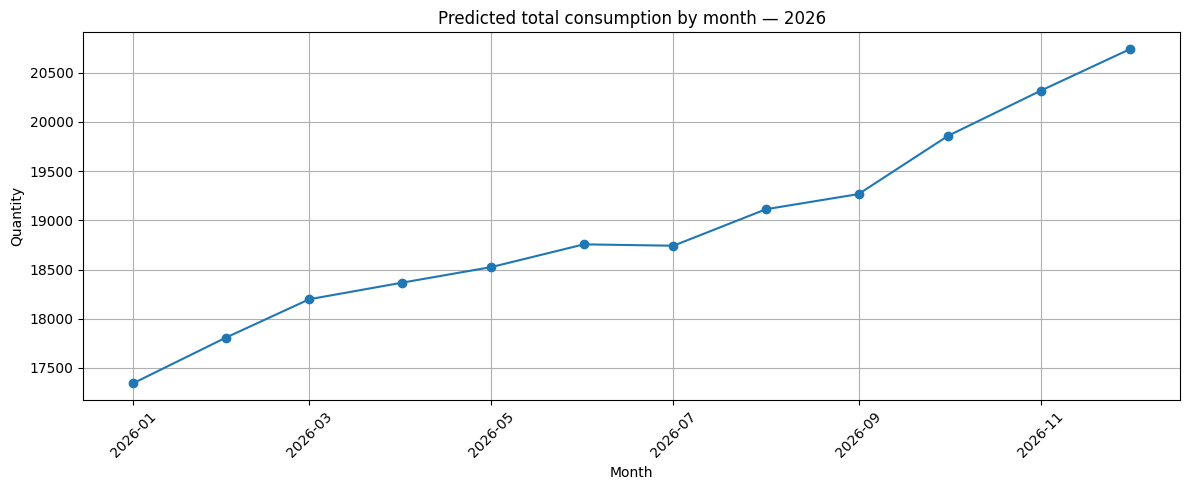

In [14]:
plt.figure(figsize=(12, 5))
monthly_total = forecast_2026.groupby("month")["predicted_consumption"].sum()
plt.plot(monthly_total.index, monthly_total.values, marker="o")
plt.title("Predicted total consumption by month — 2026")
plt.xlabel("Month")
plt.ylabel("Quantity")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Stockout classifier (second AI/ML model)

Predicts the probability that a product's stock will hit zero **next
month**, using current stock levels as features (legitimate here, since
this is one month ahead, not a multi-month recursive forecast).

In [15]:
stockout_data = data.copy()
stockout_data["next_closing_stock"] = stockout_data.groupby("product_id")["closing_stock"].shift(-1)
stockout_data["stockout_next_month"] = (stockout_data["next_closing_stock"] <= 0).astype(int)
stockout_data = stockout_data.dropna(subset=STOCK_FEATURES + ["next_closing_stock"])

stock_train = stockout_data[stockout_data["month"] < "2025-01-01"]
stock_test = stockout_data[stockout_data["month"] >= "2025-01-01"]

rf_clf = RandomForestClassifier(n_estimators=300, max_depth=15, min_samples_leaf=2,
                                 class_weight="balanced", random_state=42, n_jobs=-1)
rf_clf.fit(stock_train[STOCK_FEATURES], stock_train["stockout_next_month"])

stock_prob = rf_clf.predict_proba(stock_test[STOCK_FEATURES])[:, 1]
stock_pred = (stock_prob >= 0.40).astype(int)

print("Accuracy :", round(accuracy_score(stock_test["stockout_next_month"], stock_pred), 3))
print("Precision:", round(precision_score(stock_test["stockout_next_month"], stock_pred, zero_division=0), 3))
print("Recall   :", round(recall_score(stock_test["stockout_next_month"], stock_pred, zero_division=0), 3))
print("F1       :", round(f1_score(stock_test["stockout_next_month"], stock_pred, zero_division=0), 3))
print()
print(classification_report(stock_test["stockout_next_month"], stock_pred, zero_division=0))

Accuracy : 0.971
Precision: 0.738
Recall   : 0.765
F1       : 0.751

              precision    recall  f1-score   support

           0       0.99      0.98      0.98      5187
           1       0.74      0.76      0.75       310

    accuracy                           0.97      5497
   macro avg       0.86      0.87      0.87      5497
weighted avg       0.97      0.97      0.97      5497



In [16]:
latest = data.sort_values(["product_id", "month"]).groupby("product_id").tail(1).copy()
latest["stockout_probability"] = rf_clf.predict_proba(latest[STOCK_FEATURES])[:, 1]

def risk_label(p):
    if p >= 0.70: return "HIGH"
    if p >= 0.40: return "MEDIUM"
    return "LOW"

latest["stockout_risk"] = latest["stockout_probability"].apply(risk_label)
latest[["product_id", "closing_stock", "stockout_probability", "stockout_risk"]].head(10)

,product_id,closing_stock,stockout_probability,stockout_risk
35,P0001,795,0.000000,LOW
71,P0002,9,0.000000,LOW
107,P0003,44,0.012401,LOW
143,P0004,3,0.081075,LOW
179,P0005,12,0.000000,LOW
215,P0006,7,0.052884,LOW
251,P0007,487,0.025357,LOW
287,P0008,1,0.015833,LOW
323,P0009,25,0.000000,LOW
359,P0010,16,0.028081,LOW


## 8. How much to buy

 For each product:

- **Reorder point** = expected demand during the supplier's lead time +
  safety stock (buffer against demand variability, using a 95% one-sided
  service level — an analytical choice, not an official HAL policy).
- **Recommended order quantity for 2026** = predicted 2026 demand + safety
  stock − stock already on hand, floored at 0.

In [17]:
demand_stats = data.groupby("product_id")["quantity_consumed"].agg(
    average_monthly_demand="mean", demand_std="std"
).reset_index()

latest_stock = data.sort_values("month").groupby("product_id").tail(1)[
    ["product_id", "closing_stock", "lead_time_days"]
].rename(columns={"closing_stock": "closing_stock_dec_2025"})

Z = 1.65  # ~95% one-sided service level — analytical assumption

inv = (
    latest_stock
    .merge(demand_stats, on="product_id")
    .merge(annual_forecast_2026, on="product_id")
    .merge(products, on="product_id")
)

inv["lead_time_months"] = inv["lead_time_days"] / 30
inv["lead_time_demand"] = inv["average_monthly_demand"] * inv["lead_time_months"]
inv["safety_stock"] = Z * inv["demand_std"] * np.sqrt(inv["lead_time_months"])
inv["reorder_point"] = inv["lead_time_demand"] + inv["safety_stock"]
inv["reorder_required"] = inv["closing_stock_dec_2025"] < inv["reorder_point"]

inv["recommended_order_qty_2026"] = np.maximum(
    inv["predicted_annual_consumption_2026"] + inv["safety_stock"] - inv["closing_stock_dec_2025"],
    0
).round().astype(int)

inv[["product_id", "closing_stock_dec_2025", "reorder_point", "reorder_required",
     "recommended_order_qty_2026"]].head(10)

,product_id,closing_stock_dec_2025,reorder_point,reorder_required,recommended_order_qty_2026
0,P0487,3,16.428606,True,166
1,P0490,13,9.400943,False,25
2,P0499,1,5.895857,True,48
3,P0498,1,3.274023,True,22
4,P0492,4,3.299474,False,34
5,P0496,13,13.610550,True,49
6,P0491,246,265.620292,True,2356
7,P0488,28,17.423166,False,116
8,P0489,11,11.837060,True,103
9,P0495,2,1.849832,False,35


## 9. Risk labels

Rules are checked in priority order, so each product gets exactly one
label — and (unlike the first version) the labels actually spread across
categories instead of collapsing into one or two.

In [18]:
analysis_date = pd.Timestamp("2025-12-31")
inv["expiry_date"] = pd.to_datetime(inv["expiry_date"])
inv["days_to_expiry"] = (inv["expiry_date"] - analysis_date).dt.days

def expiry_status(d):
    if d < 0: return "EXPIRED"
    if d <= 90: return "EXPIRING_SOON"
    if d <= 180: return "EXPIRING_6M"
    return "VALID"

inv["expiry_status"] = inv["days_to_expiry"].apply(expiry_status)

inv["months_of_stock"] = inv["closing_stock_dec_2025"] / inv["average_monthly_demand"].replace(0, np.nan)
inv["excess_flag"] = inv["months_of_stock"] > 12

inv = inv.merge(latest[["product_id", "stockout_probability", "stockout_risk"]], on="product_id", how="left")

def final_risk(row):
    if row["expiry_status"] == "EXPIRED":
        return "EXPIRED STOCK"
    if row["stockout_risk"] == "HIGH" and row["criticality"] == "High":
        return "CRITICAL STOCKOUT RISK"
    if row["reorder_required"]:
        return "REORDER REQUIRED"
    if row["expiry_status"] in ["EXPIRING_SOON", "EXPIRING_6M"]:
        return "EXPIRY RISK"
    if row["excess_flag"]:
        return "POTENTIAL EXCESS"
    return "NORMAL"

inv["final_risk"] = inv.apply(final_risk, axis=1)
inv["final_risk"].value_counts()

,count
final_risk,
NORMAL,229
REORDER REQUIRED,225
EXPIRY RISK,43
CRITICAL STOCKOUT RISK,3


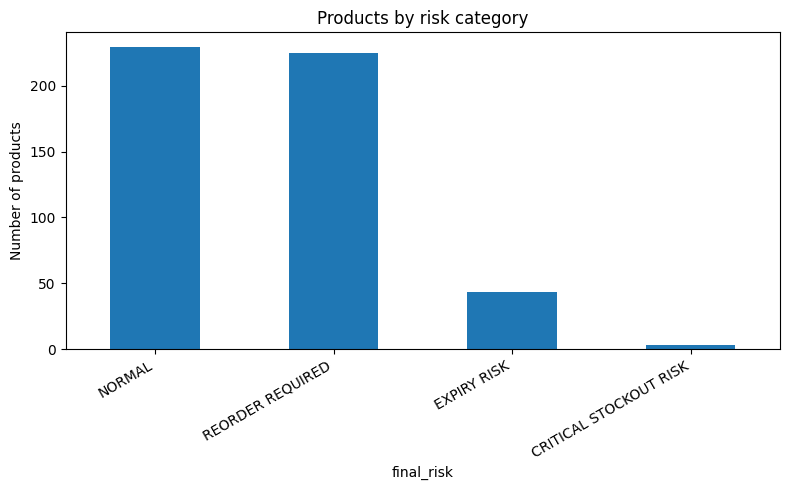

In [29]:
plt.figure(figsize=(8, 5))
inv["final_risk"].value_counts().plot(kind="bar")
plt.title("Products by risk category")
plt.ylabel("Number of products")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 10. Save outputs

In [30]:
inv["inventory_value_inr"] = (
    inv["closing_stock_dec_2025"] * inv["unit_cost_inr"]
)

final_report = inv[[
    "product_id",
    "product_name",
    "category",
    "criticality",
    "supplier_id",
    "closing_stock_dec_2025",
    "average_monthly_demand",
    "predicted_annual_consumption_2026",
    "reorder_point",
    "reorder_required",
    "recommended_order_qty_2026",
    "stockout_probability",
    "stockout_risk",
    "expiry_date",
    "expiry_status",
    "months_of_stock",
    "excess_flag",
    "inventory_value_inr",
    "final_risk"
]].copy()

In [31]:
def get_action(row):
    if row["final_risk"] == "EXPIRED STOCK":
        return "Review expired stock"
    elif row["final_risk"] == "CRITICAL STOCKOUT RISK":
        return "Prioritize stock replenishment"
    elif row["final_risk"] == "REORDER REQUIRED":
        return "Review reorder"
    elif row["final_risk"] == "EXPIRY RISK":
        return "Review expiry"
    elif row["final_risk"] == "POTENTIAL EXCESS":
        return "Review excess stock"
    else:
        return "No immediate action"

final_report["recommended_action"] = final_report.apply(
    get_action,
    axis=1
)

In [32]:
# Put recommended_action next to final_risk
cols = list(final_report.columns)
cols.remove("recommended_action")

risk_index = cols.index("final_risk")
cols.insert(risk_index + 1, "recommended_action")

final_report = final_report[cols]


# Define priority of inventory risks
priority = {
    "EXPIRED STOCK": 1,
    "CRITICAL STOCKOUT RISK": 2,
    "REORDER REQUIRED": 3,
    "EXPIRY RISK": 4,
    "POTENTIAL EXCESS": 5,
    "NORMAL": 6
}

# Add temporary priority column
final_report["_p"] = final_report["final_risk"].map(priority)

# Sort highest-priority risks first
final_report = final_report.sort_values(
    ["_p", "stockout_probability"],
    ascending=[True, False]
).drop(columns="_p")


# Round forecast values
final_report["predicted_annual_consumption_2026"] = (
    final_report["predicted_annual_consumption_2026"].round(2)
)

forecast_2026["predicted_consumption"] = (
    forecast_2026["predicted_consumption"].round(2)
)


# Save the final outputs
final_report.to_csv(
    "final_inventory_risk_report.csv",
    index=False
)

forecast_2026.to_csv(
    "consumption_forecast_2026.csv",
    index=False
)

model_comparison.to_csv(
    "model_comparison.csv",
    index=False
)

print(
    "Saved: final_inventory_risk_report.csv, "
    "consumption_forecast_2026.csv, "
    "model_comparison.csv"
)


# Display first 10 rows
final_report.head(10)

Saved: final_inventory_risk_report.csv, consumption_forecast_2026.csv, model_comparison.csv


,product_id,product_name,category,criticality,supplier_id,closing_stock_dec_2025,average_monthly_demand,predicted_annual_consumption_2026,reorder_point,reorder_required,recommended_order_qty_2026,stockout_probability,stockout_risk,expiry_date,expiry_status,months_of_stock,excess_flag,inventory_value_inr,final_risk,recommended_action
420,P0255,Avionics-Avionics-0255,Avionics,High,SUP15,1,1.333333,14.0,1.224468,True,14,0.929427,HIGH,2027-09-26,VALID,0.750000,False,52575.85,CRITICAL STOCKOUT RISK,Prioritize stock replenishment
408,P0273,Cockpit-Instruments-0273,Cockpit Instruments,High,SUP09,6,7.500000,158.0,5.954905,False,154,0.815656,HIGH,2027-11-19,VALID,0.800000,False,100443.78,CRITICAL STOCKOUT RISK,Prioritize stock replenishment
201,P0097,Rotor-Transmission-0097,Rotor & Transmission,High,SUP01,5,4.861111,96.0,4.012019,False,93,0.802979,HIGH,2029-02-13,VALID,1.028571,False,1878911.25,CRITICAL STOCKOUT RISK,Prioritize stock replenishment
302,P0381,Avionics-Avionics-0381,Avionics,Medium,SUP07,1,1.722222,17.0,1.460009,True,17,0.945032,HIGH,2026-09-13,VALID,0.580645,False,151840.77,REORDER REQUIRED,Review reorder
230,P0065,Airframe-Structures-0065,Airframe Structures,Medium,SUP07,2,2.805556,18.0,3.000552,True,18,0.942045,HIGH,2027-04-11,VALID,0.712871,False,69092.48,REORDER REQUIRED,Review reorder
481,P0316,Landing-Gear-0316,Landing Gear,Low,SUP01,3,4.305556,67.0,3.026741,True,65,0.914746,HIGH,2032-01-05,VALID,0.696774,False,370340.79,REORDER REQUIRED,Review reorder
43,P0151,Electrical-Systems-0151,Electrical Systems,Low,SUP01,28,32.500000,592.0,34.226672,True,582,0.628230,MEDIUM,2026-08-06,VALID,0.861538,False,116619.72,REORDER REQUIRED,Review reorder
439,P0303,Avionics-Avionics-0303,Avionics,Low,SUP20,1,1.833333,15.0,1.776297,True,15,0.604239,MEDIUM,2027-11-20,VALID,0.545455,False,198945.09,REORDER REQUIRED,Review reorder
109,P0187,Landing-Gear-0187,Landing Gear,Low,SUP17,2,1.388889,24.0,2.204671,True,23,0.290263,LOW,2031-11-12,VALID,1.440000,False,229882.14,REORDER REQUIRED,Review reorder
228,P0063,Electrical-Systems-0063,Electrical Systems,Medium,SUP05,0,32.638889,632.0,36.194246,True,652,0.278429,LOW,2026-01-09,EXPIRING_SOON,0.000000,False,0.00,REORDER REQUIRED,Review reorder


## 11. Look up a single product

Shows one product's history, its 2026 forecast, and its risk summary in
one place. This is the same logic used by `app.py` (the Streamlit page).

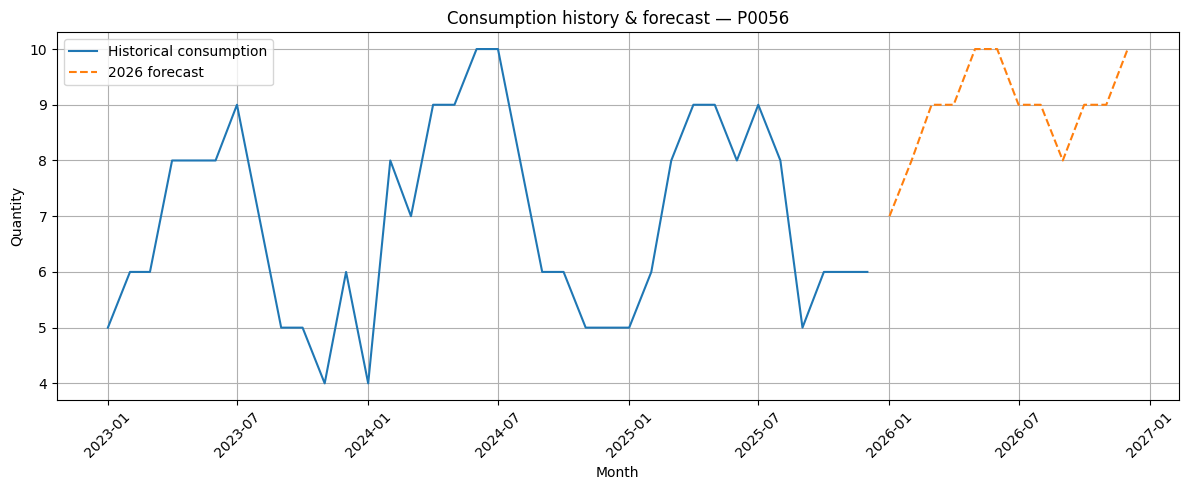

                                                        160
product_id                                            P0056
product_name                       Airframe-Structures-0056
category                                Airframe Structures
criticality                                          Medium
supplier_id                                           SUP08
closing_stock_dec_2025                                    7
average_monthly_demand                             6.916667
predicted_annual_consumption_2026                     107.0
reorder_point                                      5.476755
reorder_required                                      False
recommended_order_qty_2026                              102
stockout_probability                               0.462141
stockout_risk                                        MEDIUM
expiry_date                             2028-12-03 00:00:00
expiry_status                                         VALID
months_of_stock                         

In [35]:
def inspect_product(product_id):
    hist = data[data["product_id"] == product_id].sort_values("month")
    fcst = forecast_2026[forecast_2026["product_id"] == product_id].sort_values("month")
    report_row = final_report[final_report["product_id"] == product_id]

    plt.figure(figsize=(12, 5))
    plt.plot(hist["month"], hist["quantity_consumed"], label="Historical consumption")
    plt.plot(fcst["month"], fcst["predicted_consumption"], label="2026 forecast", linestyle="--")
    plt.title(f"Consumption history & forecast — {product_id}")
    plt.xlabel("Month")
    plt.ylabel("Quantity")
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    print(report_row.T)

inspect_product("P0056")